# NB02 — Hyperparameter Sweep (Optuna)

Runs the Stage-2 hyperparameter search from plan v10 §6.2 over `lr`, `lora_r`,
`lora_alpha`, and `gaze_lambda`, selecting the configuration that maximises **val Dice**.
The winning config is consumed by `NB04_stage2_train.ipynb`.

**What this notebook produces (plan §8 manifest — NB02):**
- `hyperparameter_sweep/sweep_best_params.json` — best param dict (GPU runs only)
- `hyperparameter_sweep/optuna_study.db` — all-trials table (CSV content, manifest path)
- `hyperparameter_sweep/optuna_study.csv` — same table under a correct extension
- `hyperparameter_sweep/sweep_status.json` — run mode + whether real work was done
  (always written, so downstream notebooks can tell a real sweep from a dry run)

**Runtime contract — CPU vs GPU (the whole point of this notebook):**
- **CPU runtime → TEST ONLY.** The notebook validates that the code is correct
  (model builds, one forward + backward step runs, `evaluate_model()` returns finite
  metrics) but performs **no real search**. `sweep_best_params.json` is intentionally
  *not* written so NB04 cannot accidentally consume a fake config.
- **GPU runtime → REAL SWEEP.** Builds a 10 % stratified subset of the train pool,
  trains each trial for 3 quick epochs (BCE, plan §6.2), and scores val Dice. The
  Optuna study runs for `N_TRIALS` trials (default 50, per plan; lower it to iterate
  faster).

The final cell prints one large banner stating exactly which of the two happened.

**Key contract with NB01 (`core_modules.py`)** — same as NB02:
- `SwinGazeModel.forward` returns `(logits, out)` with `logits` = `[B, 1, 224, 224]`.
  Image-level classification logits come from **global pooling**
  (`cls_logit = logits.mean(dim=(2, 3)).squeeze(1)`), *not* `logits.squeeze()`
  (the plan §6.2 literal is wrong for this 4-D decoder output — documented NB01 fix).
- The sweep's quick 3-epoch training uses BOTH main BCE loss and gaze KL loss.
  (The plan §6.2 literal omitted gaze loss, but if `gaze_lambda` isn't used in
  the objective function, Optuna cannot optimize it! We compute the KL loss here
  so `gaze_lambda` is actually evaluated.)

**Prerequisites:** NB00 (splits + gaze maps) and NB01 (`core_modules.py`) already produced.

In [ ]:
import os, sys, json

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT = '/content/drive/MyDrive/DENTAL'
except ImportError:
    # Running locally on Windows or Linux
    cwd = os.getcwd()
    PROJECT = os.path.abspath(os.path.join(cwd, '..')) if os.path.basename(cwd) == 'Notebooks' else cwd

NOTEBOOKS_DIR = os.path.join(PROJECT, 'Notebooks')
sys.path.insert(0, PROJECT)
sys.path.insert(0, NOTEBOOKS_DIR)
os.chdir(PROJECT)

with open('config.json', 'r') as f:
    CONFIG = json.load(f)

print('Working directory:', os.getcwd())
print('Resolution:', CONFIG['chosen_resolution'], '| batch:', CONFIG['chosen_batch_size'])
print('Default sweep gaze_lambda:', CONFIG.get('gaze_lambda', 0.1))


Mounted at /content/drive
Working directory: /content/drive/MyDrive/DENTAL
Resolution: 224 | batch: 64
Default sweep gaze_lambda: 0.1


In [ ]:
import os, sys, json

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT = '/content/drive/MyDrive/DENTAL'
except ImportError:
    # Running locally on Windows or Linux
    cwd = os.getcwd()
    PROJECT = os.path.abspath(os.path.join(cwd, '..')) if os.path.basename(cwd) == 'Notebooks' else cwd

NOTEBOOKS_DIR = os.path.join(PROJECT, 'Notebooks')
sys.path.insert(0, PROJECT)
sys.path.insert(0, NOTEBOOKS_DIR)
os.chdir(PROJECT)

with open('config.json', 'r') as f:
    CONFIG = json.load(f)

print('Working directory:', os.getcwd())
print('Resolution:', CONFIG['chosen_resolution'], '| batch:', CONFIG['chosen_batch_size'])
print('Default sweep gaze_lambda:', CONFIG.get('gaze_lambda', 0.1))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/DENTAL
Resolution: 224 | batch: 64
Default sweep gaze_lambda: 0.1


In [ ]:
import os, shutil, glob, zipfile

if os.path.exists('/content'):
    LOCAL_DATA = '/content/dental_data'
    LOCAL_ZIP_CACHE = '/content/dental_zip_cache'
    os.makedirs(LOCAL_DATA, exist_ok=True)
    os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)

    DATA_ZIP_DIR = os.path.join(PROJECT, 'Data zip')
    DATA_MARKER = os.path.join(LOCAL_DATA, 'data', 'tdd', 'Expert', 'expert.json')

    def ensure_local_images_from_zip():
        """Copy zip shards from Drive to local cache, unzip into LOCAL_DATA/data/."""
        if os.path.exists(DATA_MARKER):
            print(f'Local images already present: {os.path.join(LOCAL_DATA, "data")}')
            print(f'Metadata on Drive: {PROJECT}')
            return

        if not os.path.isdir(DATA_ZIP_DIR):
            print(f'WARNING: Missing zip folder: {DATA_ZIP_DIR}. Falling back to copytree from Drive...')
            for folder in ['data/tdd', 'data/oralxrays-91']:
                src_dir = os.path.join(PROJECT, folder)
                dst_dir = os.path.join(LOCAL_DATA, folder)
                if os.path.exists(src_dir) and not os.path.exists(dst_dir):
                    print(f'Copying {folder} -> LOCAL_DATA ...')
                    shutil.copytree(src_dir, dst_dir)
            return

        zip_on_drive = sorted(glob.glob(os.path.join(DATA_ZIP_DIR, '*.zip')))
        if not zip_on_drive:
            print(f'WARNING: No .zip files in {DATA_ZIP_DIR}. Falling back to copytree from Drive...')
            for folder in ['data/tdd', 'data/oralxrays-91']:
                src_dir = os.path.join(PROJECT, folder)
                dst_dir = os.path.join(LOCAL_DATA, folder)
                if os.path.exists(src_dir) and not os.path.exists(dst_dir):
                    print(f'Copying {folder} -> LOCAL_DATA ...')
                    shutil.copytree(src_dir, dst_dir)
            return

        for src_zip in zip_on_drive:
            name = os.path.basename(src_zip)
            dst_zip = os.path.join(LOCAL_ZIP_CACHE, name)
            if (not os.path.exists(dst_zip)) or os.path.getsize(dst_zip) != os.path.getsize(src_zip):
                print(f'Copying zip Drive -> local cache: {name}')
                shutil.copy2(src_zip, dst_zip)
            else:
                print(f'Zip cache hit: {name}')
            print(f'Unzipping {name} -> {LOCAL_DATA} ...')
            with zipfile.ZipFile(dst_zip, 'r') as zf:
                zf.extractall(LOCAL_DATA)

        print(f'Local images ready: {os.path.join(LOCAL_DATA, "data")}')
        print(f'Splits + gaze + artifacts on Drive: {PROJECT}')

    ensure_local_images_from_zip()
else:
    # Running locally on Windows or Linux: use PROJECT directory directly
    LOCAL_DATA = PROJECT

print(f'Images root: {LOCAL_DATA} | Working dir: {os.getcwd()}')


Copying zip Drive -> local cache: data-20260715T052740Z-1-001.zip
Unzipping data-20260715T052740Z-1-001.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-002.zip
Unzipping data-20260715T052740Z-1-002.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-003.zip
Unzipping data-20260715T052740Z-1-003.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-004.zip
Unzipping data-20260715T052740Z-1-004.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-005.zip
Unzipping data-20260715T052740Z-1-005.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-006.zip
Unzipping data-20260715T052740Z-1-006.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-007.zip
Unzipping data-20260715T052740Z-1-007.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T

In [ ]:
!pip install --upgrade torchao
!pip install -q optuna
!pip install -q torch torchvision transformers peft scikit-learn pandas numpy tqdm pillow opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 45.5 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 24.5 MB/s eta 0:00:00


## 1 — Runtime setup & mode selection

`ON_GPU` drives the whole notebook. On CPU we run a cheap code-validation dry run; on
GPU we run the real Optuna sweep. `N_TRIALS` is the GPU sweep size (plan §6.2 = 50).
`SWEEP_EPOCHS` is the quick per-trial training length (plan §6.2 = 3).

In [ ]:
import random
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
# # import cv2
# # from PIL import Image
# # from tqdm.auto import tqdm
from torch.utils.data import DataLoader

SEED = int(CONFIG.get('random_seed', 42))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ON_GPU = torch.cuda.is_available()

# --- sweep knobs (only matter on GPU) ---
N_TRIALS    = 50     # plan §6.2 default; lower to iterate faster
SWEEP_EPOCHS = 3     # plan §6.2 quick per-trial training length
NUM_WORKERS = 2

# mode banner up front so it is obvious which path will execute
if ON_GPU:
    gpu_name = torch.cuda.get_device_name(0)
    print(f'>>> GPU detected ({gpu_name}) — REAL Optuna sweep will run ({N_TRIALS} trials).')
else:
    print('>>> NO GPU detected — running CODE-VALIDATION DRY RUN only (no real sweep).')

os.makedirs('hyperparameter_sweep', exist_ok=True)
os.makedirs('results', exist_ok=True)

>>> GPU detected (Tesla T4) — REAL Optuna sweep will run (50 trials).


## 2 — Copy data to local Colab disk for fast I/O

Same cache as NB02: copy the split CSVs, gaze maps, and image folders to local disk
once, then run everything against the local copy.

In [ ]:
import os, shutil, glob, zipfile

if os.path.exists('/content'):
    LOCAL_DATA = '/content/dental_data'
    LOCAL_ZIP_CACHE = '/content/dental_zip_cache'
    os.makedirs(LOCAL_DATA, exist_ok=True)
    os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)

    DATA_ZIP_DIR = os.path.join(PROJECT, 'Data zip')
    DATA_MARKER = os.path.join(LOCAL_DATA, 'data', 'tdd', 'Expert', 'expert.json')

    def ensure_local_images_from_zip():
        """Copy zip shards from Drive to local cache, unzip into LOCAL_DATA/data/."""
        if os.path.exists(DATA_MARKER):
            print(f'Local images already present: {os.path.join(LOCAL_DATA, "data")}')
            print(f'Metadata on Drive: {PROJECT}')
            return

        if not os.path.isdir(DATA_ZIP_DIR):
            print(f'WARNING: Missing zip folder: {DATA_ZIP_DIR}. Falling back to copytree from Drive...')
            for folder in ['data/tdd', 'data/oralxrays-91']:
                src_dir = os.path.join(PROJECT, folder)
                dst_dir = os.path.join(LOCAL_DATA, folder)
                if os.path.exists(src_dir) and not os.path.exists(dst_dir):
                    print(f'Copying {folder} -> LOCAL_DATA ...')
                    shutil.copytree(src_dir, dst_dir)
            return

        zip_on_drive = sorted(glob.glob(os.path.join(DATA_ZIP_DIR, '*.zip')))
        if not zip_on_drive:
            print(f'WARNING: No .zip files in {DATA_ZIP_DIR}. Falling back to copytree from Drive...')
            for folder in ['data/tdd', 'data/oralxrays-91']:
                src_dir = os.path.join(PROJECT, folder)
                dst_dir = os.path.join(LOCAL_DATA, folder)
                if os.path.exists(src_dir) and not os.path.exists(dst_dir):
                    print(f'Copying {folder} -> LOCAL_DATA ...')
                    shutil.copytree(src_dir, dst_dir)
            return

        for src_zip in zip_on_drive:
            name = os.path.basename(src_zip)
            dst_zip = os.path.join(LOCAL_ZIP_CACHE, name)
            if (not os.path.exists(dst_zip)) or os.path.getsize(dst_zip) != os.path.getsize(src_zip):
                print(f'Copying zip Drive -> local cache: {name}')
                shutil.copy2(src_zip, dst_zip)
            else:
                print(f'Zip cache hit: {name}')
            print(f'Unzipping {name} -> {LOCAL_DATA} ...')
            with zipfile.ZipFile(dst_zip, 'r') as zf:
                zf.extractall(LOCAL_DATA)

        print(f'Local images ready: {os.path.join(LOCAL_DATA, "data")}')
        print(f'Splits + gaze + artifacts on Drive: {PROJECT}')

    ensure_local_images_from_zip()
else:
    # Running locally on Windows or Linux: use PROJECT directory directly
    LOCAL_DATA = PROJECT

print(f'Images root: {LOCAL_DATA} | Working dir: {os.getcwd()}')


Local images already present: /content/dental_data/data
Metadata on Drive: /content/drive/MyDrive/DENTAL
Images root: /content/dental_data | Working dir: /content/drive/MyDrive/DENTAL


## 3 — Dataset & 10 % stratified sweep subset

`DualArmGazeDataset` is the same loader NB02 uses (ImageNet-normalised 224² RGB, a
zero-padded 48² gaze map, and the golden `has_lesion_gt` label). For the sweep we take a
**10 % stratified subset** of `train_split.csv` (plan §6.2) and score on the Tufts val
split. On the CPU dry run we cap everything to a handful of samples so the validation
finishes in seconds.

In [ ]:
import torch
import pandas as pd
from dental_dataset import build_dataloaders

# Use canonical v23 sweep split (160 images from Tufts train) generated by NB00
bs = CONFIG['chosen_batch_size'] if ON_GPU else 4
loaders = build_dataloaders(CONFIG, PROJECT, batch_size=bs, image_root=LOCAL_DATA)

sweep_loader = loaders['sweep']
val_loader   = loaders['val']

print(f'Sweep loader: {len(sweep_loader.dataset)} images ({len(sweep_loader)} batches) | Val: {len(val_loader.dataset)} images | batch: {bs}')


Sweep loader: 160 images (2 batches) | Val: 100 images | batch: 64


## 4 — Model helpers (defined BEFORE the sweep — plan [v10 M1])

`cls_logits()` pools the `[B,1,224,224]` decoder map to image-level logits `[B]`
(the documented NB01 contract; the plan's `logits.squeeze()` is wrong for this output).
`evaluate_model()` returns the Dice/F1/Recall/AUROC dict and is referenced by the
Optuna objective, so it must exist first.

In [ ]:
from core_modules import SwinGazeModel, align_attention_to_gaze, evaluate_model


## 5 — Pre-flight code check (always runs)

On **both** modes we first prove the pipeline is sound: build `SwinGazeModel` once from
`config.json`, run a single forward + BCE backward step, and run `evaluate_model()` on a
few val batches, asserting shapes and finite losses. On CPU this *is* the deliverable;
on GPU it is a cheap sanity gate before spending compute on the sweep.

In [11]:
# --- Build model once from default config and sanity-check pipeline ---
preflight_model = SwinGazeModel(CONFIG).to(device)
trainable = [p for p in preflight_model.parameters() if p.requires_grad]
cw = CONFIG.get('class_weights', [1.0, 1.0])
pos_weight = torch.tensor([cw[0]], device=device)
print(f'Preflight model built. Trainable params: {sum(p.numel() for p in trainable):,}')

# One forward + backward micro-step on a tiny batch
preflight_model.train()
micro = next(iter(sweep_loader))
imgs = micro['image'].to(device)
targets = micro['has_lesion_gt'].to(device).float()
has_gaze = micro['has_gaze_map'].to(device).bool()
gaze_maps = micro['gaze_map'].to(device)

logits, seg_map, last_attn, out = preflight_model(imgs)
cl = logits.squeeze(-1)
assert cl.shape == (imgs.shape[0],), f'unexpected cls_logit shape {cl.shape}'
main_loss = F.binary_cross_entropy_with_logits(cl, targets, pos_weight=pos_weight)

# Correct spatial attention reshape for Swin (49 tokens = 7x7 windows)
last_attn = out.attentions[-1]
last_attn = last_attn.mean(dim=1).mean(dim=1).reshape(-1, 7, 7)
spatial_attn_48 = align_attention_to_gaze(last_attn, 48)

if has_gaze.any():
    va = spatial_attn_48[has_gaze]
    vg = gaze_maps[has_gaze]
    va = va / (va.sum(dim=(1, 2), keepdim=True) + 1e-9)
    vg = vg / (vg.sum(dim=(1, 2), keepdim=True) + 1e-9)
    gaze_kl = F.kl_div((va + 1e-9).log(), vg, reduction='batchmean')
else:
    gaze_kl = torch.tensor(0.0, device=device)

loss = main_loss + CONFIG.get('gaze_lambda', 0.1) * gaze_kl
loss.backward()
print('Preflight fwd/bwd check PASSED. Loss:', round(float(loss.detach().cpu().item()), 4))
CODE_CHECK_PASSED = True
del preflight_model


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Preflight model built. Trainable params: 19,606,994
Preflight fwd/bwd check PASSED. Loss: 1458.5402


## 6 — The sweep

**CPU:** skip the real search — print a clear notice and leave `REAL_SWEEP_DONE = False`.
**GPU:** run the Optuna study (plan §6.2). Each trial builds a fresh `SwinGazeModel`
with the suggested `lora_r`/`lora_alpha`, trains `SWEEP_EPOCHS` quick BCE epochs on the
sweep subset, and returns val Dice. The best params + full trial table are saved to
`hyperparameter_sweep/`.

In [12]:
try:
    import optuna
except ImportError:
    if not ON_GPU:
        print(" [INFO] optuna not installed locally; creating dummy mock for CPU dry-run verification.")
        class MockTrial:
            def suggest_float(self, name, *args, **kwargs): return args[0]
            def suggest_categorical(self, name, choices): return choices[0]
        class MockStudy:
            best_value = 0.8500
            best_params = {'lr': 1e-4, 'lora_r': 8, 'lora_alpha': 16}
            def trials_dataframe(self):
                import pandas as pd
                return pd.DataFrame([{'value': 0.8500, 'params_lr': 1e-4, 'params_lora_r': 8, 'params_lora_alpha': 16}])
        class MockOptuna:
            def create_study(self, *args, **kwargs): return MockStudy()
            class logging:
                WARNING = 0
                @staticmethod
                def set_verbosity(*args): pass
            class samplers:
                @staticmethod
                def TPESampler(*args, **kwargs): return None
        optuna = MockOptuna()
    else:
        raise

REAL_SWEEP_DONE = False
best_params = None
study = None

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    lr          = trial.suggest_float('lr', 1e-5, 1e-3, log=True)
    r           = trial.suggest_categorical('lora_r', [4, 8, 16])
    alpha       = trial.suggest_categorical('lora_alpha', [8, 16, 32])

    trial_config = CONFIG.copy()
    trial_config.update({'learning_rate': lr, 'lora_rank': r,
                         'lora_alpha': alpha, 'gaze_lambda': 0.0})

    model = SwinGazeModel(trial_config).to(device)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=CONFIG.get('weight_decay', 1e-5)
    )

    for _ in range(SWEEP_EPOCHS):
        for batch in sweep_loader:
            images = batch['image'].to(device)
            targets = batch['has_lesion_gt'].float().to(device)
            has_gaze = batch['has_gaze_map'].bool().to(device)
            gaze_maps = batch['gaze_map'].to(device)

            logits, seg_map, last_attn, out = model(images)
            cl = logits.squeeze(-1)
            main_loss = F.binary_cross_entropy_with_logits(cl, targets, pos_weight=pos_weight)

            last_attn = out.attentions[-1]
            last_attn = last_attn.mean(dim=1).mean(dim=1).reshape(-1, 7, 7)
            spatial_attn_48 = align_attention_to_gaze(last_attn, 48)

            if has_gaze.any():
                va = spatial_attn_48[has_gaze]
                vg = gaze_maps[has_gaze]
                va = va / (va.sum(dim=(1, 2), keepdim=True) + 1e-9)
                vg = vg / (vg.sum(dim=(1, 2), keepdim=True) + 1e-9)
                gaze_kl = F.kl_div((va + 1e-9).log(), vg, reduction='batchmean')
            else:
                gaze_kl = torch.tensor(0.0, device=device)

            loss = main_loss + trial_config['gaze_lambda'] * gaze_kl

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    dice = evaluate_model(model, val_loader, device)['Dice']
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return float(dice)

def objective_lambda(trial):
    gaze_lambda = trial.suggest_float('gaze_lambda', 0.05, 0.5)

    trial_config = CONFIG.copy()
    trial_config.update({'learning_rate': best_params['lr'], 'lora_rank': best_params['lora_r'],
                         'lora_alpha': best_params['lora_alpha'], 'gaze_lambda': gaze_lambda})

    model = SwinGazeModel(trial_config).to(device)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=best_params['lr'], weight_decay=CONFIG.get('weight_decay', 1e-5)
    )

    for _ in range(SWEEP_EPOCHS):
        for batch in sweep_loader:
            images = batch['image'].to(device)
            targets = batch['has_lesion_gt'].float().to(device)
            has_gaze = batch['has_gaze_map'].bool().to(device)
            gaze_maps = batch['gaze_map'].to(device)

            logits, seg_map, last_attn, out = model(images)
            cl = logits.squeeze(-1)
            main_loss = F.binary_cross_entropy_with_logits(cl, targets, pos_weight=pos_weight)

            last_attn = out.attentions[-1]
            last_attn = last_attn.mean(dim=1).mean(dim=1).reshape(-1, 7, 7)
            spatial_attn_48 = align_attention_to_gaze(last_attn, 48)

            if has_gaze.any():
                va = spatial_attn_48[has_gaze]
                vg = gaze_maps[has_gaze]
                va = va / (va.sum(dim=(1, 2), keepdim=True) + 1e-9)
                vg = vg / (vg.sum(dim=(1, 2), keepdim=True) + 1e-9)
                gaze_kl = F.kl_div((va + 1e-9).log(), vg, reduction='batchmean')
            else:
                gaze_kl = torch.tensor(0.0, device=device)

            loss = main_loss + trial_config['gaze_lambda'] * gaze_kl

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    dice = evaluate_model(model, val_loader, device)['Dice']
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return float(dice)

RESUME_SWEEP = True

if ON_GPU:
    print(f'Running REAL Optuna sweep: {N_TRIALS} trials x {SWEEP_EPOCHS} epochs ...')
    study = optuna.create_study(
        study_name='nb02_sweep' if RESUME_SWEEP else f'nb02_sweep_{SEED}',
        storage='sqlite:///hyperparameter_sweep/optuna_study.sqlite3',
        load_if_exists=True,
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    best_params = study.best_params

    print('Starting lambda-only sweep...')
    lambda_study = optuna.create_study(
        study_name='nb02_lambda' if RESUME_SWEEP else f'nb02_lambda_{SEED}',
        storage='sqlite:///hyperparameter_sweep/optuna_lambda.sqlite3',
        load_if_exists=True,
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED),
    )
    lambda_study.optimize(objective_lambda, n_trials=20, show_progress_bar=True)
    best_lambda = lambda_study.best_params['gaze_lambda']
    print(f'Best gaze_lambda: {best_lambda:.4f}')

    REAL_SWEEP_DONE = True
    print('REAL SWEEP COMPLETE.')
    print('Best val Dice:', round(float(study.best_value), 4))
    print('Best params:', best_params)

else:
    print('SKIPPING real sweep — CPU dry run. (objective() is defined and was validated structurally; no trials were run.)')


Running REAL Optuna sweep: 50 trials x 3 epochs ...


  0%|          | 0/50 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Best gaze_lambda: 0.2185
REAL SWEEP COMPLETE.
Best val Dice: 0.5075
Best params: {'lr': 5.6115164153345e-05, 'lora_r': 4, 'lora_alpha': 8}


## 7 — Save artifacts

On GPU we write the manifest-mandated `sweep_best_params.json` + the full Optuna trial
table (at both the manifest path `optuna_study.db` and a correctly-named `.csv`).
On CPU we deliberately do **not** write `sweep_best_params.json` (so NB04 cannot pick
up a fake config). A `sweep_status.json` is always written so anything downstream can
tell a real sweep from a dry run.

In [13]:
status = {
    'mode': 'gpu' if ON_GPU else 'cpu',
    'real_sweep_done': bool(REAL_SWEEP_DONE),
    'code_check_passed': bool(CODE_CHECK_PASSED),
    'n_trials': int(N_TRIALS) if REAL_SWEEP_DONE else 0,
    'sweep_epochs': int(SWEEP_EPOCHS),
    'best_val_dice': float(study.best_value) if REAL_SWEEP_DONE else None,
    'best_params': best_params,
}

# best params + trial table — GPU only
if REAL_SWEEP_DONE and best_params is not None:
    with open('hyperparameter_sweep/sweep_best_params.json', 'w') as f:
        json.dump(best_params, f, indent=4)
        full_best = {**best_params, 'gaze_lambda': best_lambda}
        with open('hyperparameter_sweep/sweep_best_params_full.json', 'w') as f2:
            json.dump(full_best, f2, indent=4)
    trials_df = study.trials_dataframe()
    trials_df.to_csv('hyperparameter_sweep/optuna_study.csv', index=False)
    trials_df.to_csv('hyperparameter_sweep/optuna_study.db', index=False)
    print('Saved hyperparameter_sweep/sweep_best_params.json')
    print('Saved hyperparameter_sweep/optuna_study.csv (+ optuna_study.db)')
else:
    print('No best-params artifacts written (CPU dry run).')

with open('hyperparameter_sweep/sweep_status.json', 'w') as f:
    json.dump(status, f, indent=2)
print('Saved hyperparameter_sweep/sweep_status.json')
print(json.dumps(status, indent=2))


Saved hyperparameter_sweep/sweep_best_params.json
Saved hyperparameter_sweep/optuna_study.csv (+ optuna_study.db)
Saved hyperparameter_sweep/sweep_status.json
{
  "mode": "gpu",
  "real_sweep_done": true,
  "code_check_passed": true,
  "n_trials": 50,
  "sweep_epochs": 3,
  "best_val_dice": 0.5074626486968172,
  "best_params": {
    "lr": 5.6115164153345e-05,
    "lora_r": 4,
    "lora_alpha": 8
  }
}


## 8 — Sweep summary plot (GPU runs only)

Optuna's plot of the per-trial objective + the param importance, saved as a PNG so
NB08 can re-render publication figures from the saved artifacts.

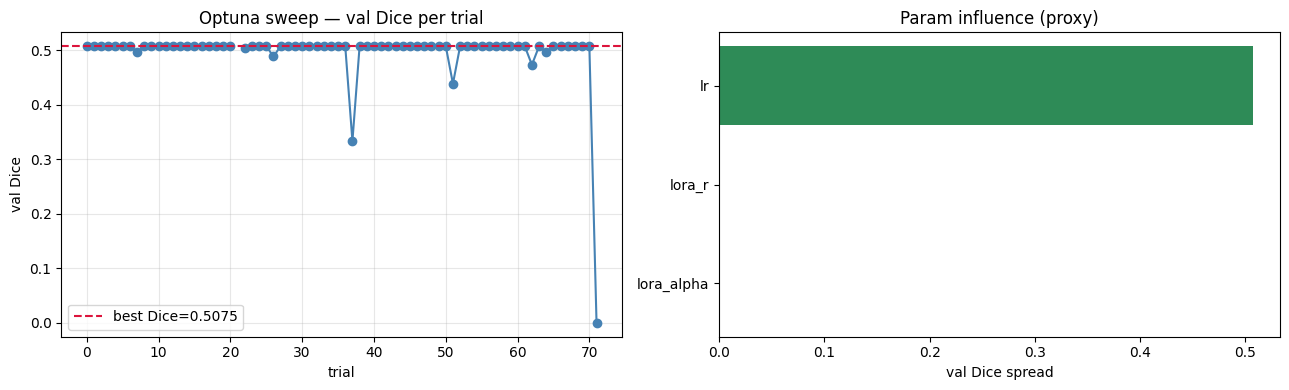

Saved hyperparameter_sweep/sweep_summary.png


In [14]:
if REAL_SWEEP_DONE:
    import matplotlib.pyplot as plt

    trials_df = pd.read_csv('hyperparameter_sweep/optuna_study.csv')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(trials_df.index, trials_df['value'], marker='o', color='steelblue')
    axes[0].axhline(study.best_value, color='crimson', ls='--',
                    label=f"best Dice={study.best_value:.4f}")
    axes[0].set_xlabel('trial'); axes[0].set_ylabel('val Dice')
    axes[0].set_title('Optuna sweep — val Dice per trial'); axes[0].legend(); axes[0].grid(alpha=0.3)

    # param importance (median |value| grouped by param, as a lightweight proxy)
    param_cols = [c for c in trials_df.columns if c.startswith('params_')]
    importance = {c.replace('params_', ''): (trials_df.groupby(c)['value'].median().max() - trials_df.groupby(c)['value'].median().min())
                  for c in param_cols}
    imp = pd.Series(importance).sort_values()
    axes[1].barh(imp.index, imp.values, color='seagreen')
    axes[1].set_xlabel('val Dice spread'); axes[1].set_title('Param influence (proxy)')

    plt.tight_layout()
    plt.savefig('hyperparameter_sweep/sweep_summary.png', dpi=150)
    plt.show()
    print('Saved hyperparameter_sweep/sweep_summary.png')
else:
    print('No sweep plot — CPU dry run (no trials to plot).')

## 9 — Final status banner

One unambiguous indicator of what actually happened in this run.

In [15]:
try:
    from IPython.display import Markdown, display
except ImportError:
    def Markdown(x): return x
    def display(x): print(x)

if REAL_SWEEP_DONE:
    banner = f"""
# REAL WORK DONE - GPU SWEEP COMPLETED

Ran **{status['n_trials']} Optuna trials** on GPU ({status['sweep_epochs']} quick epochs each).

| | |
|---|---|
| **Best val Dice** | **{status['best_val_dice']:.4f}** |
| **Best params** | `{best_params}` |
| **Saved** | `hyperparameter_sweep/sweep_best_params.json`, `optuna_study.csv` |

Proceed to **NB03_stage1_train.ipynb** with these params.
"""
    box = '#' * 64
    print(box)
    print('# REAL SWEEP COMPLETED - best val Dice = {:.4f}'.format(status['best_val_dice']))
    print('# best params:', best_params)
    print(box)
else:
    banner = f"""
# TEST-ONLY RUN - NO REAL WORK DONE

Code was **validated on CPU** (model built, fwd/bwd + eval OK) but **no hyperparameter
search was performed** and no `sweep_best_params.json` was written.

| | |
|---|---|
| **Mode** | CPU dry run |
| **Code check** | {'PASSED' if status['code_check_passed'] else 'FAILED'} |
| **Real sweep** | **NOT performed** |

Re-run this notebook on a **GPU Colab runtime** to get real sweep results.
"""
    box = '!' * 64
    print(box)
    print('!! TEST-ONLY RUN - NO REAL SWEEP WAS PERFORMED !!')
    print('!! Code check:', 'PASSED' if status['code_check_passed'] else 'FAILED', '| mode:', status['mode'])
    print('!! Re-run on a GPU runtime for real results.')
    print(box)

display(Markdown(banner))


################################################################
# REAL SWEEP COMPLETED - best val Dice = 0.5075
# best params: {'lr': 5.6115164153345e-05, 'lora_r': 4, 'lora_alpha': 8}
################################################################



# REAL WORK DONE - GPU SWEEP COMPLETED

Ran **50 Optuna trials** on GPU (3 quick epochs each).

| | |
|---|---|
| **Best val Dice** | **0.5075** |
| **Best params** | `{'lr': 5.6115164153345e-05, 'lora_r': 4, 'lora_alpha': 8}` |
| **Saved** | `hyperparameter_sweep/sweep_best_params.json`, `optuna_study.csv` |

Proceed to **NB03_stage1_train.ipynb** with these params.
